# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [1]:
import os

from pandas.api.types import is_string_dtype, is_numeric_dtype

import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

# Display all columns when looking at dataframes
pd.set_option('display.max_columns', None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Import US states shapefile

In [3]:
fp = os.path.join('/home/sarahhinkley/MEDS/eds220/eds220-inclass/week5/', 'data', 'tl_2026_us_state.shp')

states = gpd.read_file(fp)

states.head(3)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


## Create geodataframe from CSV

Known from metadata: the CRS of the power plants data has the code EPSG:4269


In [4]:
# Create points from latitude and longitude
points = gpd.points_from_xy(power_plants['longitude'],
                            power_plants['latitude'])

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants, # Data
                               geometry = points, 
                               crs = 'EPSG:4269')

In [5]:
power_plants.geometry

0         POINT (-84.29497 45.36282)
1         POINT (-83.32781 43.46590)
2         POINT (-82.93881 43.72170)
3         POINT (-85.42600 43.83930)
4         POINT (-85.85510 42.73100)
                    ...             
13440    POINT (-118.10900 34.60800)
13441     POINT (-79.28172 42.50275)
13442     POINT (-77.74272 43.18914)
13443     POINT (-75.90345 42.33782)
13444    POINT (-120.63443 37.08391)
Name: geometry, Length: 13445, dtype: geometry

In [6]:
power_plants.plot()

<Axes: >

## f-string

CRS EPSG:4269


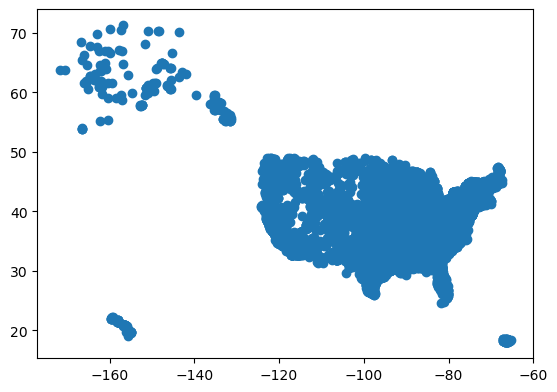

In [7]:
print('CRS', power_plants.crs)

In [8]:
# Explore CRS
print(f"ellipsoid: {power_plants.crs.ellipsoid}")

ellipsoid: GRS 1980


In [9]:
# Any expression can go inside the curly brackets
print(f"The data has {len(power_plants):,} power plants")

print(f"Average installed capacity {power_plants['install_mw'].mean():.2f} MW")

The data has 13,445 power plants
Average installed capacity 99.39 MW


## for loops

EPSG:4269


<Axes: >

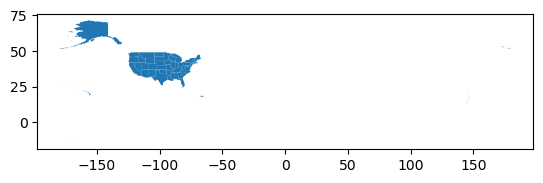

In [10]:
print(states.crs)
states.plot()

In [11]:
states.head(3)

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


In [12]:
# Simplify column names
states.columns = states.columns.str.lower()
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [13]:
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [14]:
is_string_dtype(states['region']) # says yes or no that the column is all strings

True

In [15]:
print(states['region'].dtype)

object


In [16]:
# Another way of calling the function
pd.api.types.is_string_dtype(states['region']) # went into pandas and into a sub-package (api) and into another sub-package(types)

True

In [17]:
# Check data type of codes columns
# Another way of checking, using an f string

print(f"region is string dtype? {is_string_dtype(states['region'])}")
print(f"statefp is string dtype? {is_string_dtype(states['statefp'])}")
print(f"division is string dtype? {is_string_dtype(states['division'])}")

region is string dtype? True
statefp is string dtype? True
division is string dtype? True


In [18]:
# code_cols is a variable that contains a list of column names
code_cols = ['region', 'statefp', 'division']


# Check whether code columns are strings
for cols in code_cols: # for iterator in variable (or in this case, for column in list of columns)
    print(f"{cols} is string type? {is_string_dtype(states[cols])}") 
    # cols returns the name of the column being indexed
    # is_string_dtype(states[cols]) returns whether the data type for that column in the index is a string

region is string type? True
statefp is string type? True
division is string type? True


## `assert`

We want to update the data type of the columns from strings to integers. And we want to check it worked without printing things. 

In [19]:
# Update the code columns into integers
for cols in code_cols:
    states[cols] = states[cols].astype('int')
    assert is_numeric_dtype(states[cols]) # assert is in the for loop so it iterates through all values in the index 
# if the assertion didn't generate any errors, that means the update worked for all columns in code_cols

How does `assert` work?

In [20]:
2+2 == 4

True

In [21]:
# Does nothing if the statement is True
assert 2+2 == 4

In [22]:
2+2 == 3

False

In [23]:
# Stops code from running if the statement is False
assert 2+2 == 3

AssertionError: 

In [24]:
# How you could add multiple asserts in one call
assert (2+2==4) & (1+1==2)

In [25]:
# Multiple asserts in one cell
assert 2+2==4
assert 1+1==2

In [26]:
sum = 3 + 3 

assert sum == 5, "sum is not equal to 5"

AssertionError: sum is not equal to 5

Assertions are a way to check if an output is True or False. A break in the code to check your work. What follows `assert` needs to evaluate into True or False. 

# Subset data

In [27]:
# Column names for columns with code
code_cols

['region', 'statefp', 'division']

In [28]:
for cols in code_cols: 
    print(f"{cols}: {sorted(states[cols].unique())}")

region: [1, 2, 3, 4, 9]
statefp: [1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 60, 66, 69, 72, 78]
division: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [29]:
states[states['region']==9]['name']

3                                   American Samoa
28                    United States Virgin Islands
47                                     Puerto Rico
53    Commonwealth of the Northern Mariana Islands
54                                            Guam
Name: name, dtype: object

In [30]:
# Select contiguous US states
contiguous = states[(states['region']!=9) & (~states['statefp'].isin([2,15]))] # remove anything from region 9 (the islands and terriories, as well as Hawaii and Alaska)

In [31]:
# Select the data in the power_plants data frame for the contiguous US States
power_plants['state'].value_counts()

state
California              1787
New York                1023
Texas                    921
North Carolina           918
Minnesota                782
Massachusetts            654
Illinois                 408
New Jersey               401
Florida                  321
Colorado                 300
Iowa                     298
Oregon                   286
Michigan                 274
Georgia                  267
Pennsylvania             261
Wisconsin                252
Virginia                 241
Maine                    231
Indiana                  208
South Carolina           207
Maryland                 205
Ohio                     202
Kansas                   185
Arizona                  174
Connecticut              171
Alaska                   152
Idaho                    145
New Mexico               145
Washington               142
Oklahoma                 140
Missouri                 130
Nebraska                 130
Utah                     122
Vermont                  117
Nevada  

In [32]:
# Select power plants in the contiguous US states
power_plants = power_plants[~power_plants['state'].isin(['Puerto Rico', 'Hawaii', 'Alaska'])] 
# the ~ means you are selecting everything that is not in Puerto Rico, Hawaii, Alaska

In [33]:
power_plants['state'].unique()

array(['Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana',
       'Wyoming', 'Nebraska', 'Nevada', 'New Hampshire', 'Vermont',
       'New Jersey', 'New Mexico', 'New York', 'North Carolina',
       'North Dakota', 'Ohio', 'Georgia', 'Alabama', 'Texas',
       'California', 'Kentucky', 'Washington', 'Arizona', 'Kansas',
       'South Carolina', 'Florida', 'Utah', 'Oklahoma', 'Arkansas',
       'Illinois', 'Colorado', 'Connecticut', 'Massachusetts', 'Delaware',
       'Maryland', 'Idaho', 'Maine', 'Indiana', 'Iowa', 'Louisiana',
       'Wisconsin', 'Oregon', 'Pennsylvania', 'Rhode Island',
       'South Dakota', 'Tennessee', 'West Virginia', 'Virginia',
       'District of Columbia'], dtype=object)

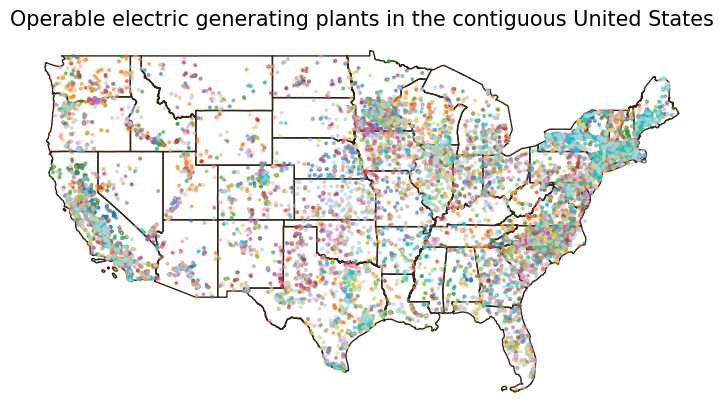

In [34]:
fig, ax = plt.subplots(figsize=(9, 5)) # Update figure size

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Operable electric generating plants in the contiguous United States',
              fontsize=15)

# Add states
contiguous.plot(ax=ax,
               color='none',
               edgecolor='#362312')

# Add electric power plants colored by energy source
power_plants.plot(ax=ax,
                  #column='primsource',
                  legend=True,
                  markersize=4,
                  cmap='tab20',
                  alpha=0.5,
                  legend_kwds={
                      'title': 'Primary energy source',
                      'title_fontsize': 'small',
                      'fontsize': 'small',
                      'loc': 'upper left',
                      'bbox_to_anchor': (0, 0),
                      'ncols': 6
                  })

plt.show()

# for with zip

often, we need to simulataneously iterate over two lists
zip() lets you combine two or more lists to iterate over them

# iterate over a single list

In [37]:
numbers = [1,2,3]
for x in numbers:
    print(x)

print('\n') # blank line

1
2
3




# iterate over two lists in pairs using zip()

In [38]:
numbers = [1,2,2]
letters = ['a', 'b', 'c']
for x, letter in zip (numbers, letters):
    print(x, letter)

1 a
2 b
2 c


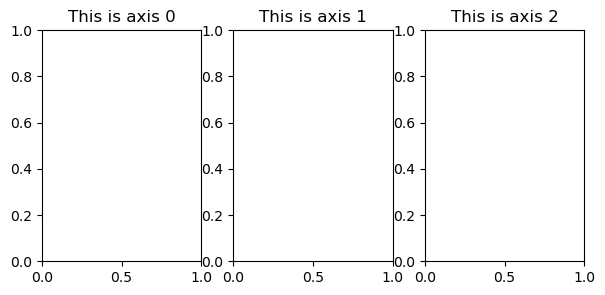

In [39]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7,3))

axes[0].set_title('This is axis 0')
axes[1].set_title('This is axis 1')
axes[2].set_title('This is axis 2')

plt.show()

# Use a for loop to write the axes labels

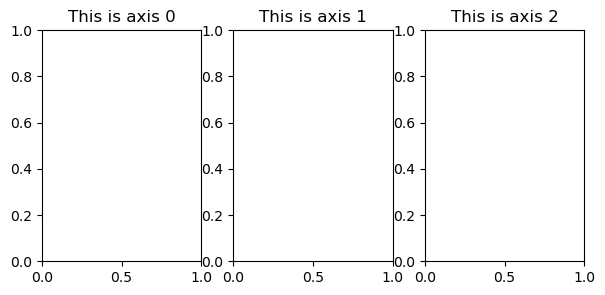

In [41]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7,3))

for ax, i in zip(axes, [0,1,2]):
    ax.set_title(f'This is axis {i}')

plt.show()

In [47]:
# Select power plants in California
ca_power_plants = power_plants[power_plants['state']=='California']

# Check
ca_power_plants['state'].unique()

array(['California'], dtype=object)

In [48]:
# Create a list named top_sources with California's top 3 electric primary sources

# Check column names
ca_power_plants.columns

Index(['objectid', 'plant_code', 'plant_name', 'utility_id', 'utility_name',
       'sector_name', 'street_address', 'city', 'county', 'state', 'zip',
       'primsource', 'source_desc', 'tech_desc', 'install_mw', 'total_mw',
       'bat_mw', 'bio_mw', 'coal_mw', 'geo_mw', 'hydro_mw', 'hydrops_mw',
       'ng_mw', 'nuclear_mw', 'crude_mw', 'solar_mw', 'wind_mw', 'other_mw',
       'source', 'period', 'longitude', 'latitude', 'geometry'],
      dtype='object')

In [51]:
ca_power_plants['primsource'].value_counts()

primsource
solar             865
natural gas       310
hydroelectric     238
wind              109
batteries         103
biomass            98
geothermal         33
petroleum          13
other              10
pumped storage      6
nuclear             1
coal                1
Name: count, dtype: int64

In [76]:
top_sources = ca_power_plants[ca_power_plants['primsource'].isin(['solar', 'natural gas', 'hydroelectric']).tolist()]

# Check
top_sources['primsource'].value_counts()

primsource
solar            865
natural gas      310
hydroelectric    238
Name: count, dtype: int64

In [77]:
# Isolate the California state boundary in a variable named ca_boundary
ca_boundary = states[states['name']=='California']

In [78]:
ca_boundary

,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
37,4,9,6,01779778,06,0400000US06,CA,California,00,G4000,A,403676534536,20288534055,+37.1626642,-119.5713456,"MULTIPOLYGON (((-119.49229 33.98322, -119.4945..."


ValueError: aspect must be finite and positive 

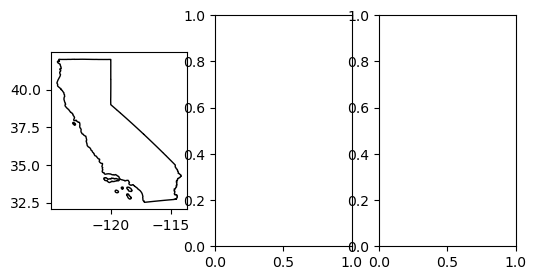

In [79]:
# Create plot 

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(6, 3)) # Update figure size

for ax, source in zip(axes, top_sources):
    ca_boundary.plot(ax=ax, color='none')
    
    subset = ca_power_plants[ca_power_plants['primsource'] == source] # for the primary sources in CA, check that the source matches the one we are iterating on
    subset.plot(ax=ax, markersize=5, alpha=0.5)
    ax.set_title(source)
    ax.axis('off')

plt.show()